### Issue #1491

This notebook is in relation to issue **#1491: Ecocounter Open Data aggregate vol by direction-of-travel(flow_direction), not by lane(direction_main)**. Prior to implementing the change, I will evaluate which sites are the most affected by using counterflow directions (in place of direction_main).

For a quick analysis, I set percentage_change = (counterflow + existing_flow) and create a few visualizations. This concludes that there are significant changes  (5%-10% of volume) to some multi-use sites. There also exists an unvalidated site where it is possible that the counterflow is improperly assigned.

In [11]:
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotly

import folium

from sqlalchemy import create_engine, Column, Integer, String, MetaData, Table, text
from sqlalchemy.engine import URL

import configparser

In [12]:
### Functions

def get_connection(config_path):
    config = configparser.ConfigParser()
    config.read(config_path)
    connect_url = URL.create("postgresql+psycopg2", **config['DBSETTINGS'])
    engine = create_engine(connect_url)
    return engine

### Initial Setup
config_path='/data/home/dboucau/data/config.cfg'

engine = get_connection(config_path)

### Daily Average for September

In [18]:
query = """
WITH counter_flows AS (
    SELECT
        flow_id,
        site_id,
        CASE
            WHEN TRIM(REGEXP_REPLACE(flow_direction, '\s*\((In|Out)\)$', '')) != direction_main::text THEN 'counterflow'
            ELSE 'flow'
        END AS flow_type
    FROM ecocounter.flows
	WHERE mode_counted = 'bike'
),
daily_counts AS (
	SELECT 
		SUM(volume) AS daily_volume, 
		flow_id,
		datetime_bin::date AS date
	FROM ecocounter.counts_unfiltered
		WHERE datetime_bin::date > '2026-01-01'
		GROUP BY (datetime_bin::date, flow_id)
),
calculated_groups AS (
	SELECT c.site_id, site_description,
		ROUND(AVG(CASE WHEN c.flow_type = 'counterflow' THEN d.daily_volume ELSE 0 END)) AS counter_flow,
		ROUND(AVG(CASE WHEN c.flow_type = 'flow' THEN d.daily_volume ELSE 0 END)) AS existing_flow
		FROM counter_flows c
			LEFT JOIN ecocounter.sites s
				ON s.site_id = c.site_id
			LEFT JOIN daily_counts d
				ON d.flow_id = c.flow_id
		WHERE date_decommissioned IS NULL
		GROUP BY (c.site_id, s.site_description)
)
SELECT site_id, counter_flow, existing_flow, site_description,
	ROUND(counter_flow / (existing_flow + counter_flow), 2) AS percentage_change
	FROM calculated_groups
    ORDER BY percentage_change DESC
	;
"""

df = pd.read_sql(query, con=engine)
df['site_id'] = df.site_id.apply(lambda x: str(int(x)))
df.head(10)

,site_id,counter_flow,existing_flow,site_description,percentage_change
0,300051579,126.0,10.0,"Millwood Rd, north of Pape Ave/Donlands Ave",0.93
1,300026120,4.0,6.0,"Keele St, south of Sheppard Ave W (multi-use p...",0.40
2,300062143,13.0,36.0,"Steeles Ave E, east of Midland Ave",0.27
3,300024652,3.0,10.0,"Keele St, north of Four Winds Dr (multi-use path)",0.23
4,300060828,11.0,40.0,"Steeles Ave E, east of Midland Ave",0.22
5,300024437,1.0,5.0,"Murray Ross Pkwy, north of Shoreham Dr (multi-...",0.17
6,300026125,3.0,23.0,"Sheppard Ave W, west of Sentinel Rd (multi-use...",0.12
7,300066342,1.0,10.0,"Chesswood Dr, north of Vanley Cres",0.09
8,300066351,3.0,34.0,"Sheppard Ave E, east of Willowdale Ave",0.08
9,300066447,86.0,930.0,"Queens Quay W, east of Stadium Rd",0.08


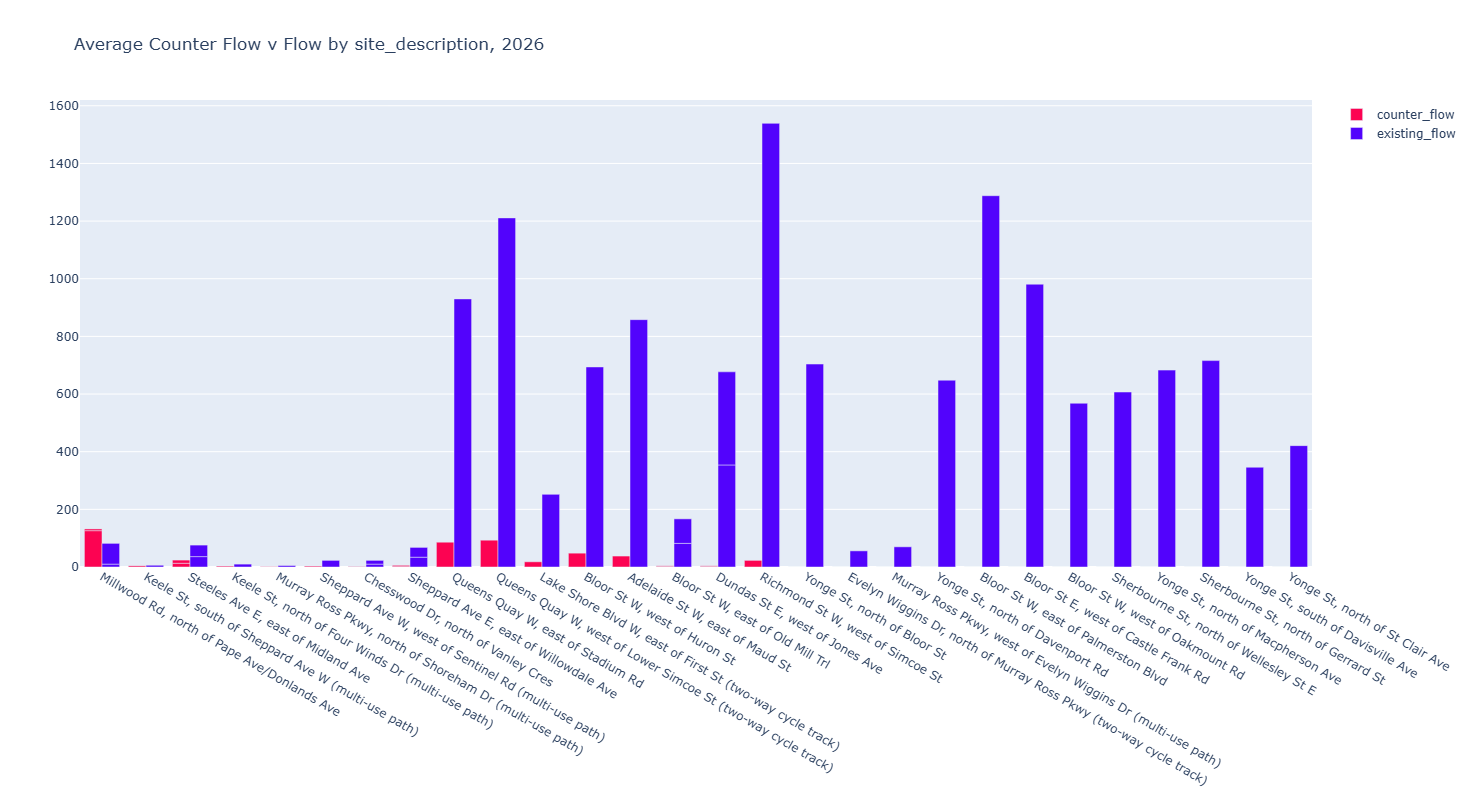

In [19]:
fig = go.Figure(data=[
    go.Bar(name='counter_flow', x=df.site_description, y=df.counter_flow, marker_color='#fc0352'),
    go.Bar(name='existing_flow', x=df.site_description, y=df.existing_flow, marker_color='#5203fc')
])

# Change the bar mode
fig.update_layout(
    width=800,
    height=800,
    barmode='group', 
    title='Average Counter Flow v Flow by site_description, 2026')
fig.show()

The volumes never break 200 but for some sites this is a very significant number. Lets plot it out over time to assess if the average value is misleading.

### Counter Flow Volume over Time

In [20]:
site_query = """
    WITH counter_flows AS (
        SELECT
            flow_id,
            site_id,
            CASE
                WHEN TRIM(REGEXP_REPLACE(flow_direction, '\s*\((In|Out)\)$', '')) != direction_main::text THEN 'counterflow'
                ELSE 'flow'
            END AS flow_type
        FROM ecocounter.flows
    	WHERE mode_counted = 'bike'
    	AND site_id = {site_id_}
    ),
    daily_counts AS (
    	SELECT 
    		SUM(volume) AS daily_volume, 
    		flow_id,
    		datetime_bin::date AS date_
    	FROM ecocounter.counts_unfiltered
    		WHERE datetime_bin::date > '2026-01-01'
    		GROUP BY (datetime_bin::date, flow_id)
    )
    SELECT c.flow_id, c.flow_type, s.site_description, date_, daily_volume
    		FROM counter_flows c
    			LEFT JOIN ecocounter.sites s
    				ON s.site_id = c.site_id
    			LEFT JOIN daily_counts d
    				ON d.flow_id = c.flow_id
    	ORDER BY date_
    """

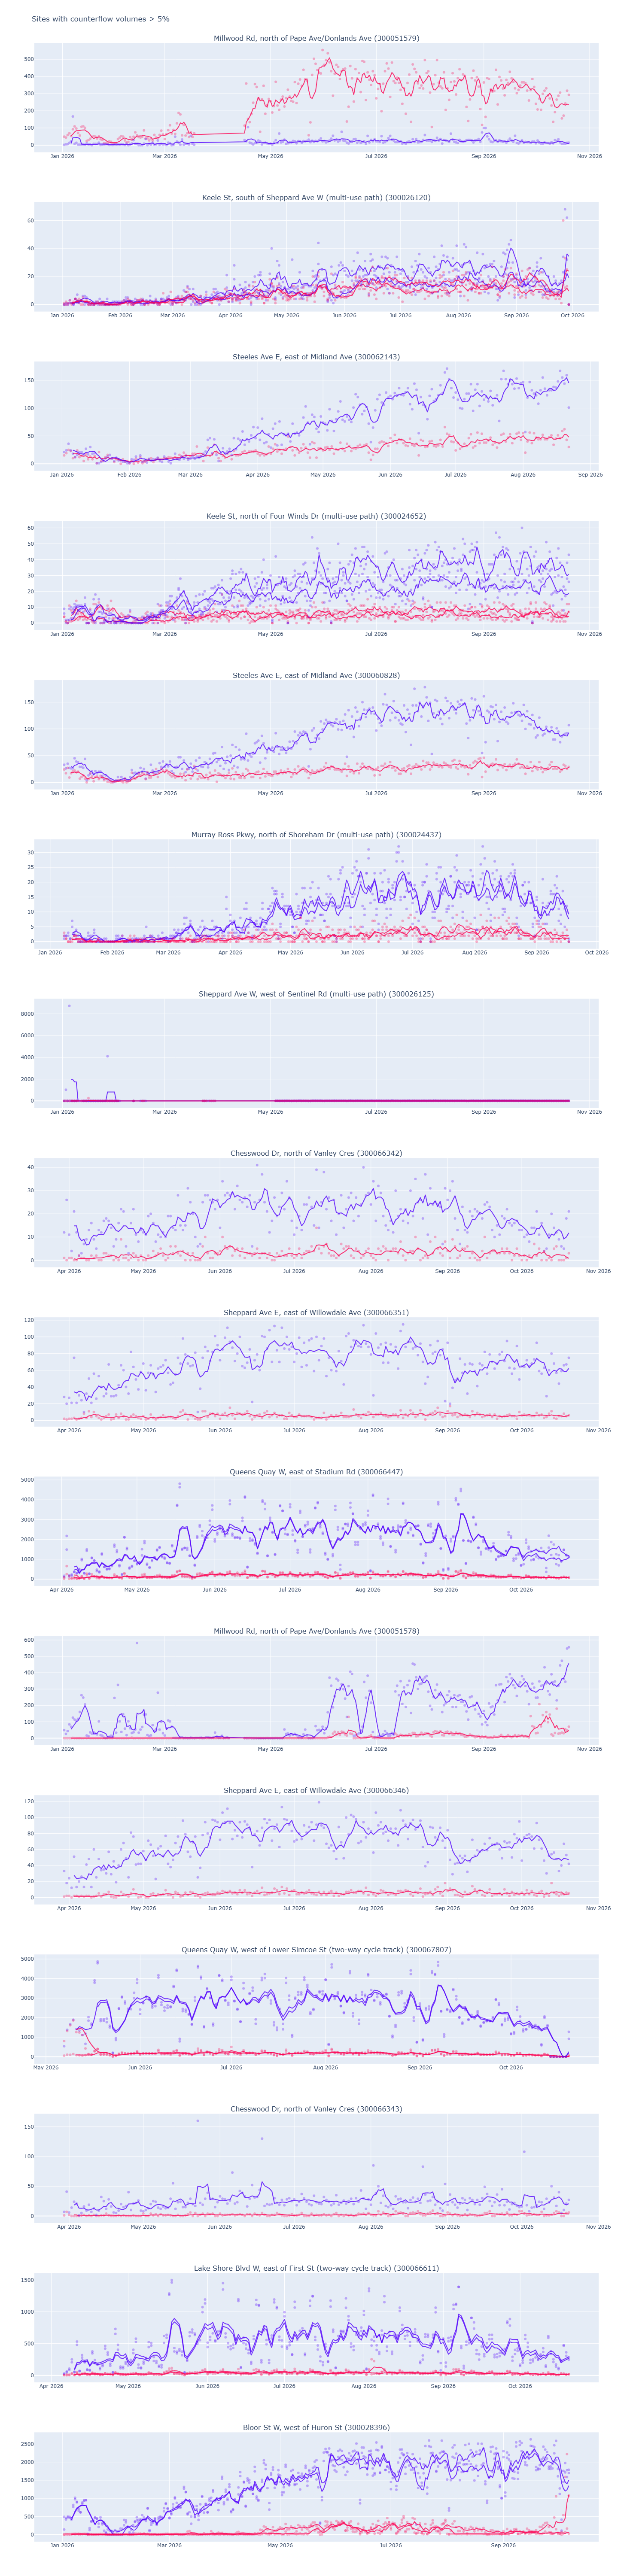

In [22]:
df["site_name"] = df.site_description + ' (' +  df.site_id + ')'
subject_sites = df.loc[df.percentage_change > 0.05, 'site_id'] #Let's look at all sites where this would make a difference of 5%
subject_site_names = df.loc[df.percentage_change > 0.05, "site_name"]

# Initiate the facet grid
fig = make_subplots(
    rows=len(subject_sites),
    cols=1,
    subplot_titles=subject_site_names,
    vertical_spacing=0.02
)

# add my plots in a looop
for i, site in enumerate(subject_sites):

    specify_site_query = site_query.format(site_id_=site)

    # print(f"Site: {site}")
    site_volumes = pd.read_sql(specify_site_query, con=engine)
    site_flow_info = site_volumes.drop_duplicates('flow_id')

    for flow_id, flow_type in zip(site_flow_info.flow_id, site_flow_info.flow_type):

        if flow_type == 'counterflow':
            colour='#fc0352'
        else:
            colour='#5203fc'
            
        temp_volumes = site_volumes[site_volumes.flow_id == flow_id].copy()
        temp_volumes['rolling_avg'] = temp_volumes.daily_volume.rolling(window=5).mean()
    
        fig.add_trace(
            go.Scatter(
                x=temp_volumes.date_,
                y=temp_volumes.daily_volume,
                mode="markers",
                name=f"{flow_type}",
                marker_color=colour,
                opacity=.3
                
            ),
            row = i + 1,
            col = 1
        )

        fig.add_trace(
            go.Scatter(
                x=temp_volumes.date_,
                y=temp_volumes.rolling_avg,
                mode='lines',
                name='5-Day Rolling Average',
                marker_color=colour,
                opacity=.8
                
            ),
            row = i + 1,
            col = 1
        )

fig.update_layout(
    title="Sites with counterflow volumes > 5% ",
    height=6000,
    showlegend=False
)

fig.show()

The more extreme cases aren't even published as they exist in anomalous ranges. That being said, a few of these actually do merit a change to our methodology.

Let's do a quick cross comparison to see which (published) sites would have an impact > 5%.

In [34]:
query = """
SELECT s.site_description
FROM ecocounter.anomalous_ranges a
JOIN ecocounter.sites s
ON a.site_id = s.site_id
WHERE a.time_range @> CURRENT_TIMESTAMP::timestamp;
"""

anomalous_ranges_sites = [ x for x in pd.read_sql(query, con=engine)['site_description']]

query = """
SELECT site_description
FROM ecocounter.sites 
WHERE date_decommissioned IS NULL;
"""

valid_sites = [ x for x in pd.read_sql(query, con=engine)['site_description']]

df['multisite'] = (df.groupby('site_description')['site_id']
                    .transform("nunique"))


impacted_sites = df.loc[((~df.site_description.isin(anomalous_ranges_sites)) & 
        (df.site_description.isin(valid_sites)) & 
        (df.multisite == 1))]

impacted_sites


,site_id,counter_flow,existing_flow,site_description,percentage_change,site_name,multisite
5,300024437,1.0,5.0,"Murray Ross Pkwy, north of Shoreham Dr (multi-...",0.17,"Murray Ross Pkwy, north of Shoreham Dr (multi-...",1
9,300066447,86.0,930.0,"Queens Quay W, east of Stadium Rd",0.08,"Queens Quay W, east of Stadium Rd (300066447)",1
12,300067807,93.0,1211.0,"Queens Quay W, west of Lower Simcoe St (two-wa...",0.07,"Queens Quay W, west of Lower Simcoe St (two-wa...",1
14,300066611,18.0,252.0,"Lake Shore Blvd W, east of First St (two-way c...",0.07,"Lake Shore Blvd W, east of First St (two-way c...",1
15,300028396,48.0,694.0,"Bloor St W, west of Huron St",0.06,"Bloor St W, west of Huron St (300028396)",1
16,300066507,38.0,858.0,"Adelaide St W, east of Maud St",0.04,"Adelaide St W, east of Maud St (300066507)",1
20,300067687,23.0,1539.0,"Richmond St W, west of Simcoe St",0.01,"Richmond St W, west of Simcoe St (300067687)",1
22,300028395,0.0,704.0,"Yonge St, north of Bloor St",0.00,"Yonge St, north of Bloor St (300028395)",1
25,300028595,0.0,648.0,"Yonge St, north of Davenport Rd",0.00,"Yonge St, north of Davenport Rd (300028595)",1
26,300031255,0.0,1288.0,"Bloor St W, east of Palmerston Blvd",0.00,"Bloor St W, east of Palmerston Blvd (300031255)",1


Finally, let's map them.

In [31]:
query = """
    SELECT
        site_id,
        ST_Y(ST_Centroid(geom)) AS lat,
        ST_X(ST_Centroid(geom)) AS lon
    FROM ecocounter.sites;
"""

locations = pd.read_sql(query, con=engine)
locations['site_id'] = locations.site_id.apply(lambda x: str(int(x)))

df_locations = impacted_sites.merge(locations, how='left')

In [32]:
m = folium.Map(
    location=[df_locations.lat.mean(), df_locations.lon.mean()],
    tiles="https://{s}.tile-cyclosm.openstreetmap.fr/cyclosm/{z}/{x}/{y}.png",
    attr='&copy; <a href="https://openstreetmap.org">OpenStreetMap</a> contributors. Design by <a href="https://github.com">CyclOSM</a>',
    zoom_start=10
)

for _, row in df_locations.iterrows():
    
    folium.CircleMarker(
        location=[row.lat, row.lon],
        radius=row.counter_flow / 10 ,
        color='red',
        fill=True,
        fill_color='red',
        fill_opacity=0.6,
        popup=f"daily_avg: {row.counter_flow}<br>site_id: {row.site_id}<br> % of total count: {row.	percentage_change * 100} %"
    ).add_to(m)

m